# ML4: Implement Gradient Descent Algorithm to find the local minima of a
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;function. For example, find the local minima of the function  
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;y = (x + 3)^2 starting from the point x = 2.  

## Theory

### 1. OPTIMISATION IN ML (Unit III)
&nbsp;&nbsp;&nbsp;Training a model = finding parameters that minimise a COST (loss) function  
&nbsp;&nbsp;&nbsp;J(theta), e.g. MSE for regression. When a closed-form solution is costly or  
&nbsp;&nbsp;&nbsp;unavailable, iterative methods such as GRADIENT DESCENT are used.  

### 2. GRADIENT DESCENT
&nbsp;&nbsp;&nbsp;The gradient dJ/dtheta points in the direction of steepest INCREASE of J.  
&nbsp;&nbsp;&nbsp;Moving opposite to it decreases J:  
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;theta\_new = theta\_old - alpha \* dJ/dtheta  
&nbsp;&nbsp;&nbsp;alpha = LEARNING RATE (step size).  
&nbsp;&nbsp;&nbsp;Repeat until the change |theta\_new - theta\_old| &lt; precision (tolerance) or  
&nbsp;&nbsp;&nbsp;max iterations reached.  

### 3. FOR y = (x + 3)^2
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;dy/dx = 2(x + 3)  
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;x\_new = x - alpha \* 2(x + 3)  
&nbsp;&nbsp;&nbsp;Analytical minimum: dy/dx = 0 -&gt; x = -3, y = 0.  
&nbsp;&nbsp;&nbsp;Starting at x = 2 with alpha = 0.01, x approaches -3.  
&nbsp;&nbsp;&nbsp;Since x\_new + 3 = (1 - 2 alpha)(x + 3), the error shrinks by factor  
&nbsp;&nbsp;&nbsp;(1 - 2 alpha) each step -&gt; converges if 0 &lt; alpha &lt; 1.  

### 4. EFFECT OF LEARNING RATE
&nbsp;&nbsp;&nbsp;- too small : very slow convergence (many iterations)  
&nbsp;&nbsp;&nbsp;- too large : overshoots, oscillates, may DIVERGE  
&nbsp;&nbsp;&nbsp;- suitable  : smooth fast convergence  
&nbsp;&nbsp;&nbsp;For non-convex functions GD can get stuck in a LOCAL minimum or saddle  
&nbsp;&nbsp;&nbsp;point; result depends on starting point.  

### 5. VARIANTS
&nbsp;&nbsp;&nbsp;- Batch GD      : gradient using all m training samples per update.  
&nbsp;&nbsp;&nbsp;- Stochastic GD : one random sample per update (noisy, fast).  
&nbsp;&nbsp;&nbsp;- Mini-batch GD : small batch (e.g. 32) - used in deep learning.  
&nbsp;&nbsp;&nbsp;- Momentum, RMSProp, Adam : adaptive improvements.  

### 6. GD FOR LINEAR REGRESSION
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;J(b0,b1) = (1/2m) SUM (b0 + b1 x\_i - y\_i)^2  
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;b0 := b0 - alpha (1/m) SUM (y\_hat\_i - y\_i)  
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;b1 := b1 - alpha (1/m) SUM (y\_hat\_i - y\_i) x\_i  
&nbsp;&nbsp;&nbsp;Lasso / Ridge add penalty gradients (L1: lambda sign(b), L2: 2 lambda b).  

### Conclusion
Gradient descent starting from x = 2 converges to the local
(and global) minimum x = -3, y = 0 of y = (x+3)^2.

In [1]:
%matplotlib inline

In [2]:
import numpy as np
import matplotlib.pyplot as plt


def f(x):
    return (x + 3) ** 2


def df(x):
    return 2 * (x + 3)


def gradient_descent(x0, alpha=0.01, precision=1e-6, max_iters=10000):
    x = x0
    history = [x]
    for i in range(1, max_iters + 1):
        prev = x
        x = x - alpha * df(prev)
        history.append(x)
        if abs(x - prev) < precision:
            break
    return x, i, history

### Run the program
Enter your own values when prompted, or just press Enter to use the sample data.


First 10 iterations:
 Iter            x      y=(x+3)^2     gradient
    0     2.000000      25.000000    10.000000
    1     1.900000      24.010000     9.800000
    2     1.802000      23.059204     9.604000
    3     1.705960      22.146060     9.411920
    4     1.611841      21.269076     9.223682
    5     1.519604      20.426820     9.039208
    6     1.429212      19.617918     8.858424
    7     1.340628      18.841049     8.681255
    8     1.253815      18.094943     8.507630
    9     1.168739      17.378383     8.337478
   10     1.085364      16.690199     8.170728

Converged after 571 iterations
Local minimum at x = -2.999951, y = 0.00000000
Analytical minimum: x = -3, y = 0

Effect of learning rate (starting at x = 2):
  alpha = 0.001  iterations = 4602   x_min = -2.999501
  alpha = 0.01   iterations = 571    x_min = -2.999951
  alpha = 0.1    iterations = 63     x_min = -2.999996
  alpha = 0.5    iterations = 2      x_min = -3.000000
  alpha = 0.9    iterations = 73   

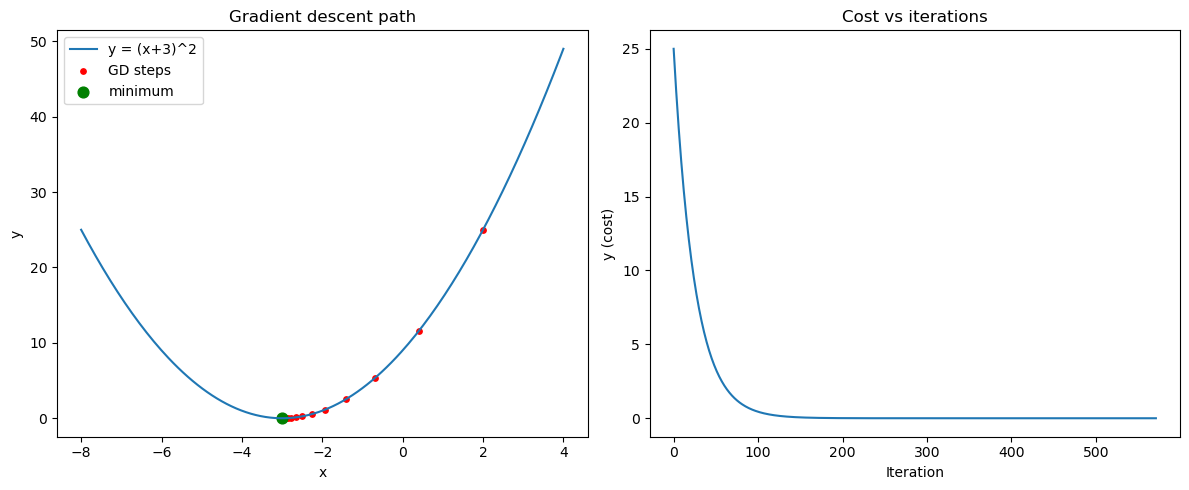

In [3]:
def main():
    try:
        x0 = float(input("Starting point x0 (Enter for 2): ") or 2)
        alpha = float(input("Learning rate (Enter for 0.01): ") or 0.01)
    except Exception:  # bad input, no input, or notebook without stdin
        x0, alpha = 2.0, 0.01
    x_min, iters, hist = gradient_descent(x0, alpha)

    print("\nFirst 10 iterations:")
    print(f"{'Iter':>5} {'x':>12} {'y=(x+3)^2':>14} {'gradient':>12}")
    for i, x in enumerate(hist[:11]):
        print(f"{i:>5} {x:>12.6f} {f(x):>14.6f} {df(x):>12.6f}")

    print(f"\nConverged after {iters} iterations")
    print(f"Local minimum at x = {x_min:.6f}, y = {f(x_min):.8f}")
    print("Analytical minimum: x = -3, y = 0")

    # effect of learning rate
    print("\nEffect of learning rate (starting at x = 2):")
    for a in [0.001, 0.01, 0.1, 0.5, 0.9]:
        xm, it, _ = gradient_descent(x0, a)
        print(f"  alpha = {a:<6} iterations = {it:<6} x_min = {xm:.6f}")

    xs = np.linspace(-8, 4, 200)
    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(xs, f(xs), label="y = (x+3)^2")
    h = np.array(hist)
    plt.scatter(h[::max(1, len(h) // 30)], f(h[::max(1, len(h) // 30)]),
                c="red", s=15, label="GD steps")
    plt.scatter([x_min], [f(x_min)], c="green", s=60, label="minimum")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.legend()
    plt.title("Gradient descent path")

    plt.subplot(1, 2, 2)
    plt.plot(f(h))
    plt.xlabel("Iteration")
    plt.ylabel("y (cost)")
    plt.title("Cost vs iterations")
    plt.tight_layout()
    plt.show()


if __name__ == "__main__":
    main()